In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.optim import Adam
from torch.utils.data import DataLoader

from datasets.coin_detection_dataset import CoinDetectionDataset
from datasets.preprocessing import prepare_dataset
from models.background_classifier import BackgroundClassifier

device = torch.device("mps")

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

In [ ]:
train_ds = CoinDetectionDataset(
    PROJECT_ROOT / "data/raw/train.pkl"
)

val_ds = CoinDetectionDataset(
    PROJECT_ROOT / "data/raw/val.pkl"
)

config = {
    "offset": 15,
    "bg_percent": 0.52,
    "iou_threshold": 0.4,
}

bg_train_ds = prepare_dataset(train_ds, config, num_of_crops_per_image=128)

bg_val_ds = prepare_dataset(val_ds, config, num_of_crops_per_image=64)

train_loader = DataLoader(bg_train_ds, batch_size=32, shuffle=True)

val_loader = DataLoader(bg_val_ds, batch_size=32)

In [4]:
model = BackgroundClassifier().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

epochs = 10

train_losses = []
train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0

In [ ]:
for epoch in range(epochs):
    model.train()

    total_loss = 0
    train_correct = 0
    train_total = 0

    for crops, labels, _ in train_loader:
        crops = crops.to(device)

        targets = (labels != 9).float().unsqueeze(1).to(device)

        optimizer.zero_grad()

        logits = model(crops)
        loss = criterion(logits, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.sigmoid(logits) > 0.5

        train_correct += (
            predictions == targets.bool()
        ).sum().item()

        train_total += targets.numel()

    train_loss = total_loss / len(train_loader)
    train_accuracy = train_correct / train_total

    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for crops, labels, _ in val_loader:
            crops = crops.to(device)

            targets = (labels != 9).float().unsqueeze(1).to(device)

            logits = model(crops)
            predictions = torch.sigmoid(logits) > 0.5

            val_correct += (
                predictions == targets.bool()
            ).sum().item()

            val_total += targets.numel()

    val_accuracy = val_correct / val_total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{epochs}"
        f"Loss: {train_loss:.4f}"
        f"Train Acc: {train_accuracy:.4f}"
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(model.state_dict(), CHECKPOINT_DIR / "background_best.pth")

Epoch 1/10 | Loss: 0.3830 | Train Acc: 0.8283 | Val Acc: 0.5365
Epoch 2/10 | Loss: 0.2528 | Train Acc: 0.8990 | Val Acc: 0.5399
Epoch 3/10 | Loss: 0.1665 | Train Acc: 0.9369 | Val Acc: 0.6693
Epoch 4/10 | Loss: 0.1032 | Train Acc: 0.9608 | Val Acc: 0.7491
Epoch 5/10 | Loss: 0.0700 | Train Acc: 0.9751 | Val Acc: 0.7491
Epoch 6/10 | Loss: 0.0604 | Train Acc: 0.9793 | Val Acc: 0.7882
Epoch 7/10 | Loss: 0.0476 | Train Acc: 0.9830 | Val Acc: 0.8681
Epoch 8/10 | Loss: 0.0431 | Train Acc: 0.9835 | Val Acc: 0.8976
Epoch 9/10 | Loss: 0.0430 | Train Acc: 0.9851 | Val Acc: 0.8637
Epoch 10/10 | Loss: 0.0379 | Train Acc: 0.9869 | Val Acc: 0.8915


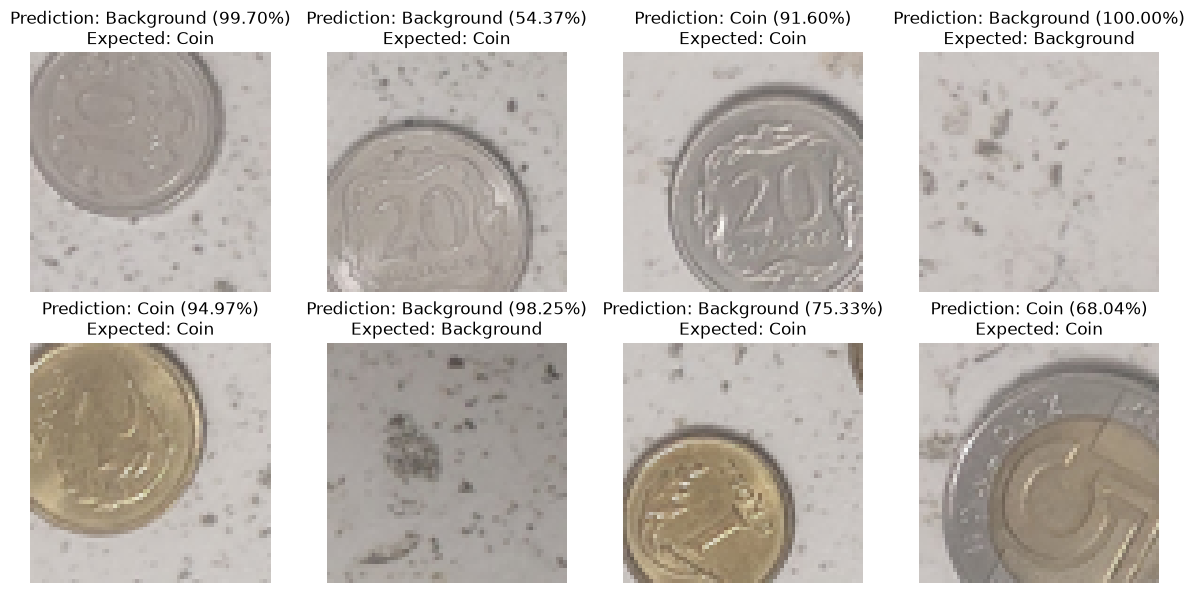

In [12]:
model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "background_best.pth",
        map_location=device
    )
)
model.eval()

crops, labels, _ = next(iter(val_loader))


with torch.no_grad():
    probabilities = torch.sigmoid(model(crops.to(device))).squeeze(1).cpu()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    prediction = "Coin" if probabilities[i] > 0.5 else "Background"
    confidence = probabilities[i] if probabilities[i] > 0.5 else 1 - probabilities[i]
    expected = "Coin" if labels[i] != 9 else "Background"

    ax.imshow(crops[i].permute(1, 2, 0))
    ax.set_title(f"Prediction: {prediction} ({confidence:.2%})\n" f"Expected: {expected}")
    ax.axis("off")

plt.tight_layout()
plt.show()

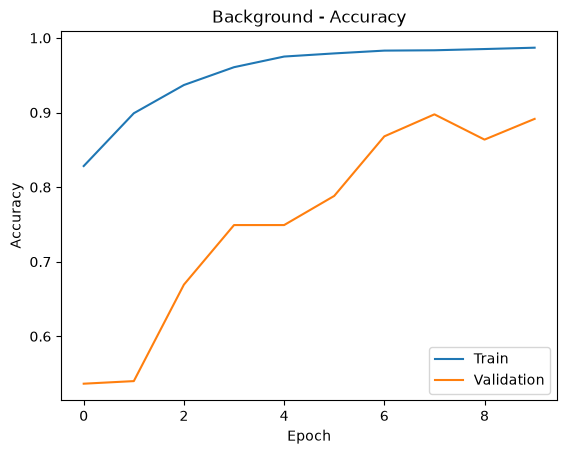

In [13]:
plt.plot(train_accuracies, label="Train")
plt.plot(val_accuracies, label="Validation")

plt.title("Background - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()